# Expectation-Maximization con mezclas de gaussianas

El algoritmo Expectation-Maximization (EM) ajusta un modelo de mezcla de gaussianas (GMM) alternando dos pasos:

- **E (expectation):** calcula la probabilidad de que cada punto pertenezca a cada gaussiana con los parámetros actuales.
- **M (maximization):** recalcula la media, la covarianza y el peso de cada gaussiana usando esas probabilidades.

Se repite hasta que el modelo deja de mejorar. En este notebook aplico `GaussianMixture` de scikit-learn, que implementa EM, a los mismos cuatro conjuntos de datos del notebook de K-Means, para comparar ambos métodos.

> **Base:** los datos y la primera figura provienen del ejemplo [*Demonstration of k-means assumptions*](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_assumptions.html) de scikit-learn (licencia BSD-3-Clause).

## 1. Datos y grupos reales

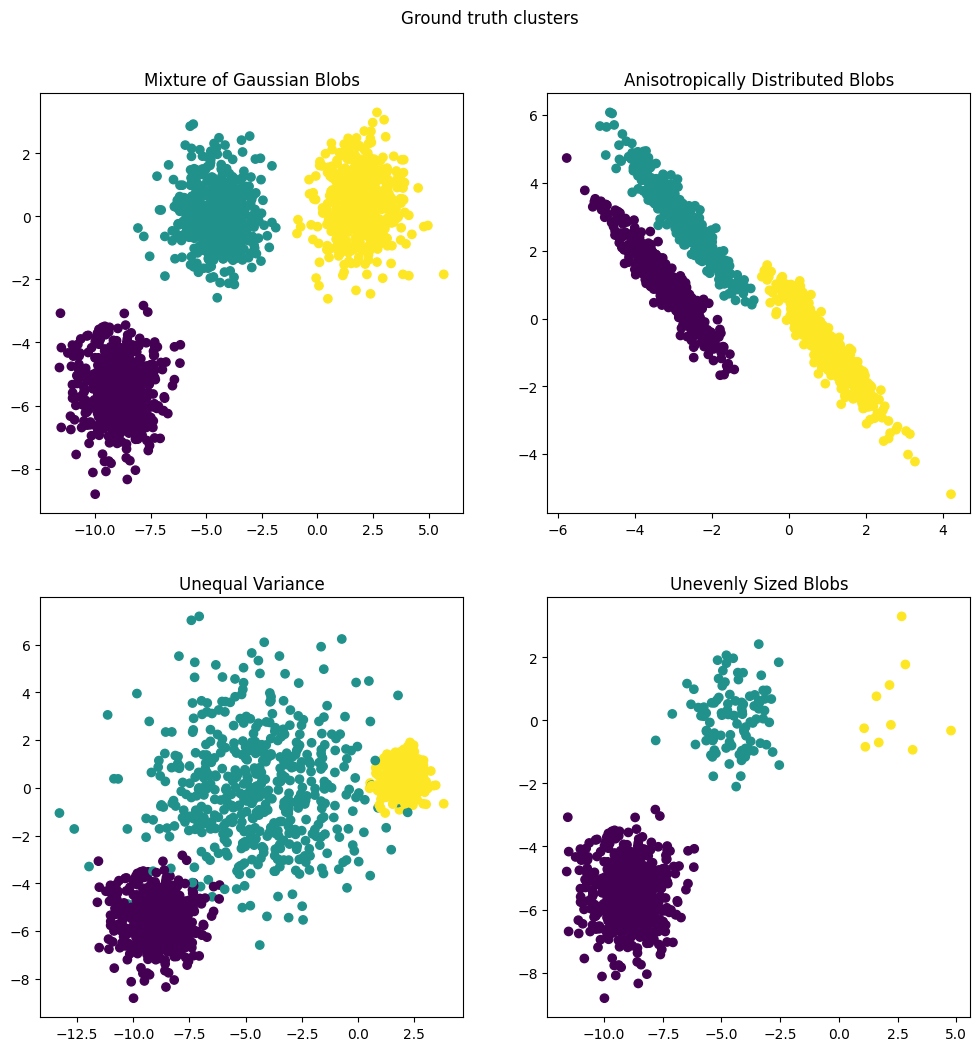

In [2]:

import numpy as np

from sklearn.datasets import make_blobs



n_samples = 1500
random_state = 170
transformation = [[0.60834549, -0.63667341], [-0.40887718, 0.85253229]]

X, y = make_blobs(n_samples=n_samples, random_state=random_state)
X_aniso = np.dot(X, transformation)  # Anisotropic blobs
X_varied, y_varied = make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)  # Unequal variance
X_filtered = np.vstack(
    (X[y == 0][:500], X[y == 1][:100], X[y == 2][:10])
)  # Unevenly sized blobs
y_filtered = [0] * 500 + [1] * 100 + [2] * 10

import matplotlib.pyplot as plt

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(12, 12))

axs[0, 0].scatter(X[:, 0], X[:, 1], c=y)
axs[0, 0].set_title("Mixture of Gaussian Blobs")

axs[0, 1].scatter(X_aniso[:, 0], X_aniso[:, 1], c=y)
axs[0, 1].set_title("Anisotropically Distributed Blobs")

axs[1, 0].scatter(X_varied[:, 0], X_varied[:, 1], c=y_varied)
axs[1, 0].set_title("Unequal Variance")

axs[1, 1].scatter(X_filtered[:, 0], X_filtered[:, 1], c=y_filtered)
axs[1, 1].set_title("Unevenly Sized Blobs")

plt.suptitle("Ground truth clusters").set_y(0.95)
plt.show()

## 2. GMM con 3 componentes en cada conjunto

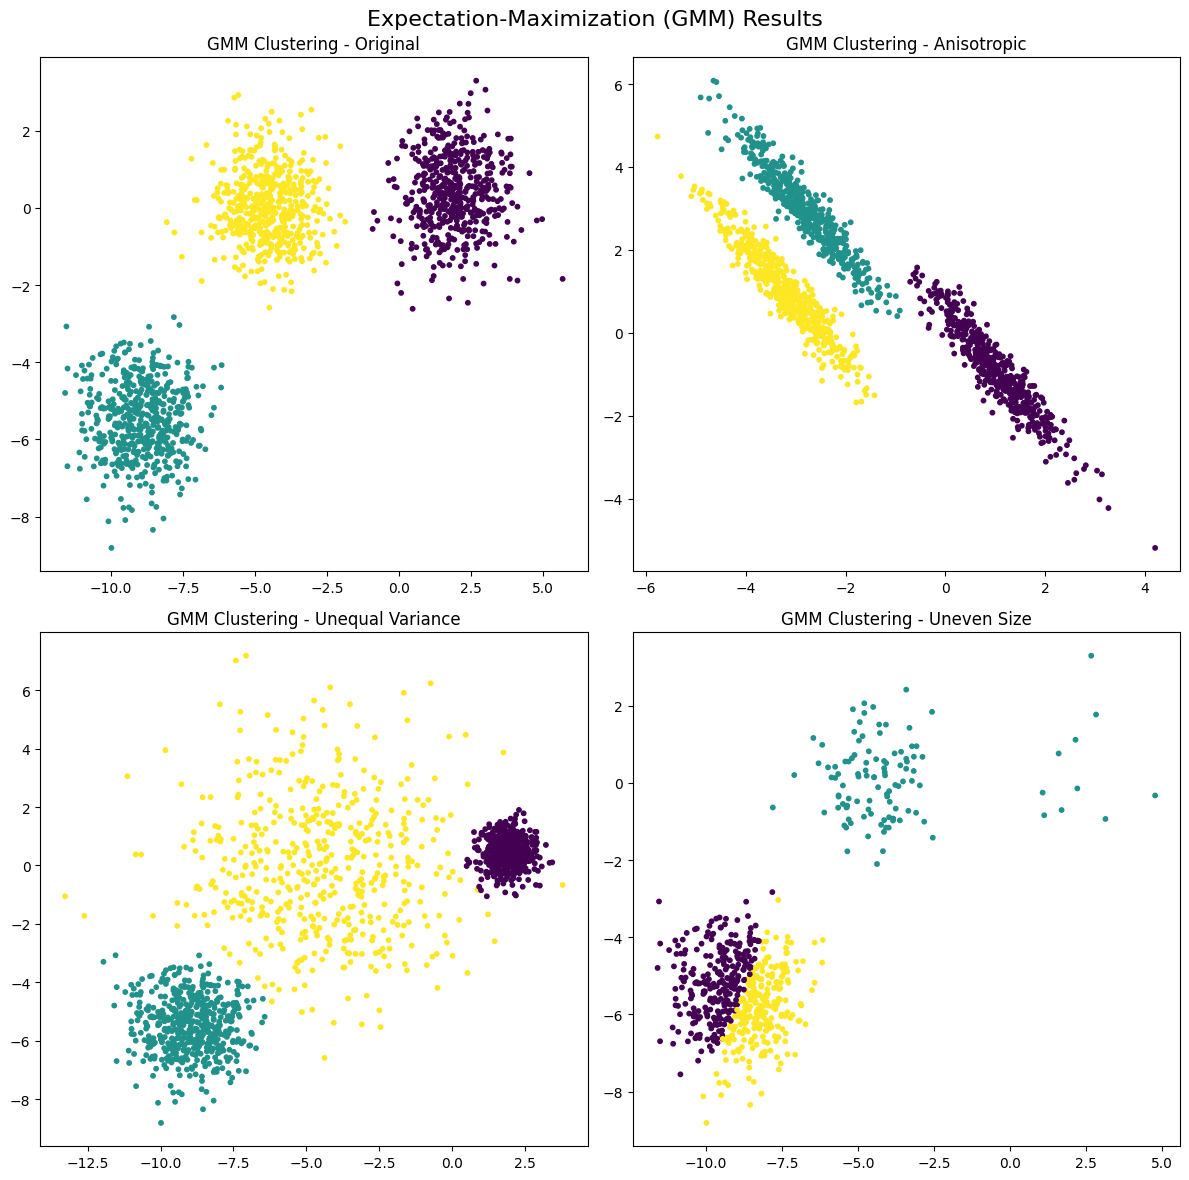

In [3]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.mixture import GaussianMixture

# Data generation
n_samples = 1500
random_state = 170
transformation = [[0.60834549, -0.63667341], [-0.40887718, 0.85253229]]

X, y = make_blobs(n_samples=n_samples, random_state=random_state)
X_aniso = np.dot(X, transformation)  # Anisotropic blobs
X_varied, y_varied = make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)  # Unequal variance
X_filtered = np.vstack(
    (X[y == 0][:500], X[y == 1][:100], X[y == 2][:10])
)  # Unevenly sized blobs
y_filtered = [0] * 500 + [1] * 100 + [2] * 10

# Apply EM algorithm (Gaussian Mixture Model) to each dataset
datasets = [("Original", X), ("Anisotropic", X_aniso), ("Unequal Variance", X_varied), ("Uneven Size", X_filtered)]
results = []

for name, data in datasets:
    gmm = GaussianMixture(n_components=3, random_state=0)
    gmm.fit(data)
    labels = gmm.predict(data)
    results.append((name, data, labels))

# Plot results
fig, axs = plt.subplots(2, 2, figsize=(12, 12))
axs = axs.ravel()

for i, (name, data, labels) in enumerate(results):
    axs[i].scatter(data[:, 0], data[:, 1], c=labels, cmap='viridis', s=10)
    axs[i].set_title(f"GMM Clustering - {name}")

plt.suptitle("Expectation-Maximization (GMM) Results", fontsize=16)
plt.tight_layout()
plt.show()

## Resultados

- **Original, anisotrópicos y varianza desigual:** GMM recupera los tres grupos. Al estimar una covarianza por grupo, se adapta a grupos alargados y a grupos con dispersiones distintas, donde K-Means falla.
- **Tamaños desiguales:** GMM falla. Divide el grupo grande (500 puntos) en dos componentes y agrupa en uno solo el grupo mediano (100) con el pequeño (10). Con tan pocos puntos, al algoritmo le resulta más verosímil usar dos gaussianas para describir la zona más densa que dedicar una a 10 puntos aislados.

## Conclusiones

- Ningún algoritmo de clustering es el mejor en todos los casos: GMM gana con grupos alargados o de varianza desigual, y K-Means con varias inicializaciones gana en este caso de tamaños muy desiguales.
- Antes de elegir un algoritmo conviene visualizar los datos y preguntarse qué forma tienen los grupos.